<div style="
background: linear-gradient(135deg,#0F172C,#1EA78A);
padding:30px;
border-radius:18px;
color:white;
text-align:center;
box-shadow:0px 4px 20px rgba(0,0,0,0.25);">

<h1 style="margin:0;font-size:38px;">
🔍 Residual Diagnostics Checking
</h1>

<h3 style="margin-top:10px;color:#CBD5E1;">
Validating the ETS / ARIMA / SARIMA models
</h3>

<p style="margin-top:25px;font-size:16px;color:#E2E8F0;">
To check if the residuals of the final models look like white noise? If not, the model is missing correlation.
</p>

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

In [2]:
residuals = pd.read_csv('../outputs/models/residuals.csv', index_col=0)

genres = residuals.columns.tolist()

residuals.head()

,Action,Adventure,Comedy,Drama,Romance,Sci-Fi,Thriller
date,,,,,,,
2000-01-01,-0.288857,NaN,NaN,-0.077236,0.444770,-0.018373,NaN
2000-02-01,0.324401,-0.203823,NaN,-0.140208,-0.020757,0.009001,NaN
2000-03-01,0.029785,0.235546,NaN,0.505239,-0.225407,0.018100,NaN
2000-04-01,-0.316823,0.016937,NaN,0.318672,0.281338,0.036308,NaN
2000-05-01,0.098258,0.194763,NaN,-0.303464,-0.043873,0.001716,NaN


In [3]:
display(residuals.shape)
residuals.describe().round(3)

(276, 7)

,Action,Adventure,Comedy,Drama,Romance,Sci-Fi,Thriller
count,276.000,275.000,264.000,276.000,276.000,276.000,264.000
mean,-0.000,0.010,-0.164,0.000,-0.000,-0.000,0.069
std,0.445,0.408,0.581,0.649,0.316,0.038,0.405
min,-1.210,-1.141,-2.045,-2.523,-1.304,-0.115,-1.191
25%,-0.287,-0.271,-0.541,-0.450,-0.203,-0.027,-0.178
50%,0.028,0.026,-0.167,0.034,-0.001,0.002,0.077
75%,0.274,0.263,0.218,0.390,0.205,0.022,0.324
max,1.701,1.200,1.384,1.558,1.051,0.117,1.663


In [4]:
display(residuals.isna().sum()) # Identifying burn-in values in the residuals

Action        0
Adventure     1
Comedy       12
Drama         0
Romance       0
Sci-Fi        0
Thriller     12
dtype: int64

In [5]:
residuals_clean = residuals.dropna() # dropping intial burn-in values from residuals
display(residuals_clean.shape)

(264, 7)

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Histogram of Residuals

</div>

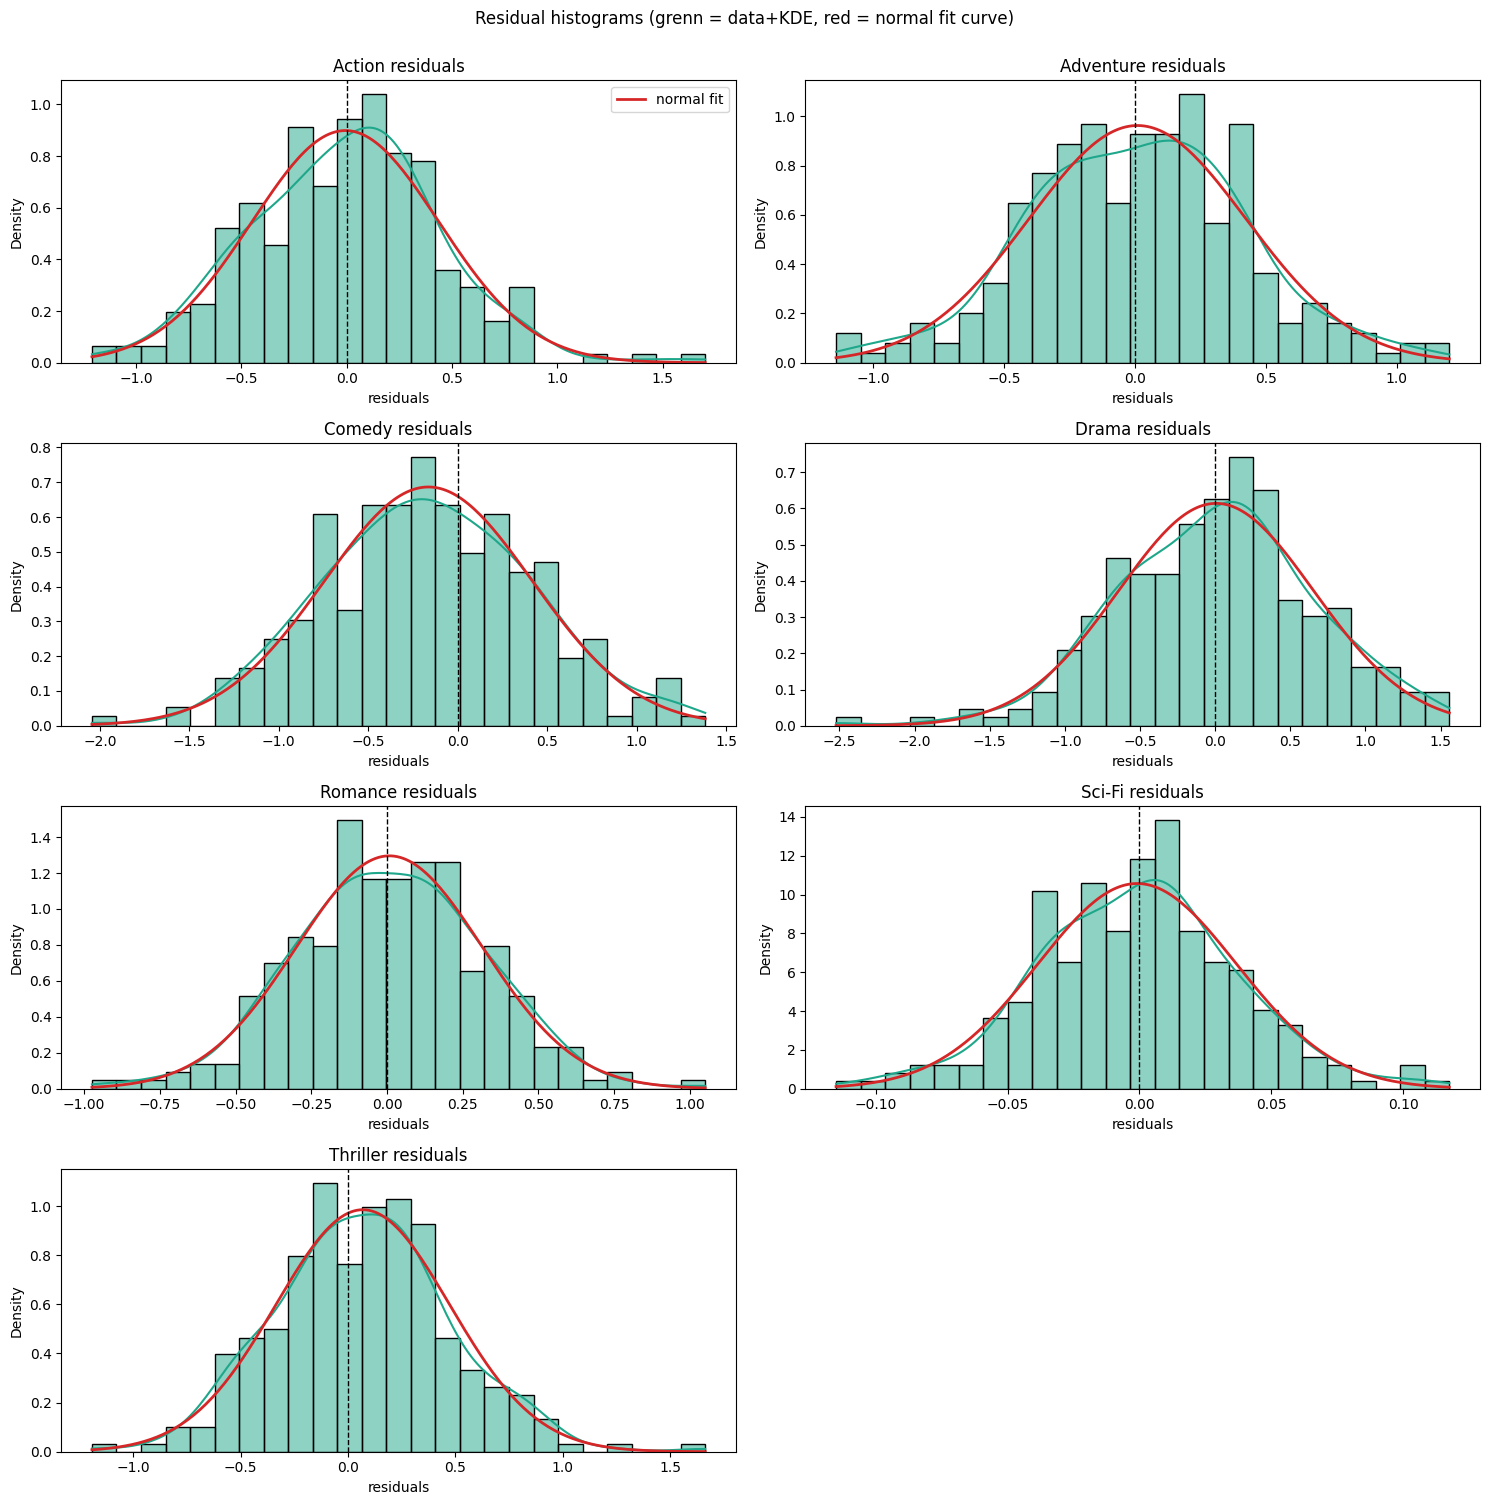

In [6]:
# histogram with normal curve
fig, axes = plt.subplots(4, 2, figsize = (15, 15))

for ax, g in zip(axes.ravel(), genres):
    r = residuals_clean[g]
    sns.histplot(r, bins= 25, stat = "density", kde = True, color = "#1EA78A", ax = ax)
    x = np.linspace(r.min(), r.max(), 200)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), color = "tab:red", lw = 2, label = "normal fit")
    ax.axvline(0, color = "k", ls="--", lw =1)
    ax.set_title(f"{g} residuals")
    ax.set_xlabel("residuals")

axes.ravel()[0].legend()
axes.ravel()[-1].axis("off")
fig.suptitle("Residual histograms (grenn = data+KDE, red = normal fit curve)", y = 1.0)
plt.tight_layout()
plt.savefig("../outputs/figures/residual_histograms.png", dpi = 300)
plt.show()

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Residuals vs Time scatter plot

</div>

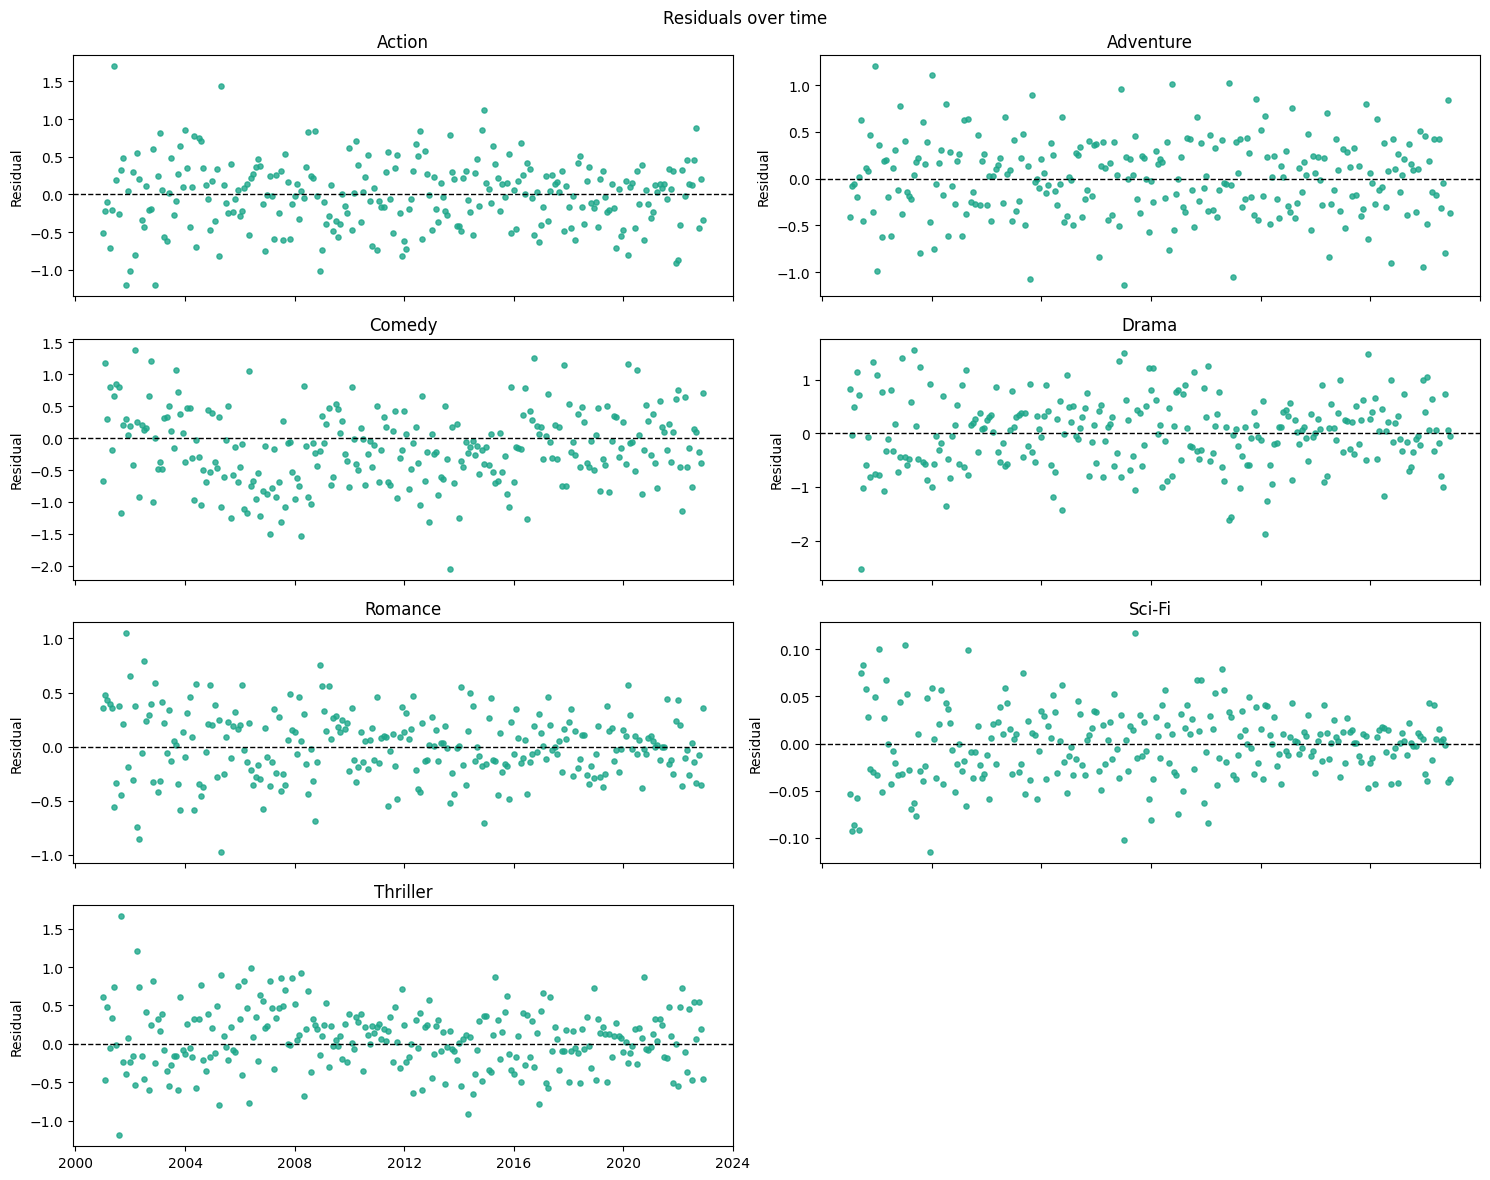

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(15, 12), sharex=True)

for ax, g in zip(axes.ravel(), genres):
    r = residuals_clean[g]
    ax.scatter(pd.to_datetime(r.index), r, color="#1EA78A", s=14, alpha=0.8)
    ax.axhline(0, color="black", ls="--", lw=1)
    ax.set_title(g)
    ax.set_ylabel("Residual")

axes.ravel()[-1].axis("off")
fig.suptitle("Residuals over time")
fig.tight_layout()
plt.show()

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Q-Q plot of Residuals

</div>

A Q-Q Plot (Quantile-Quantile Plot) is a graphical technique used to check whether residuals follow a normal distribution.

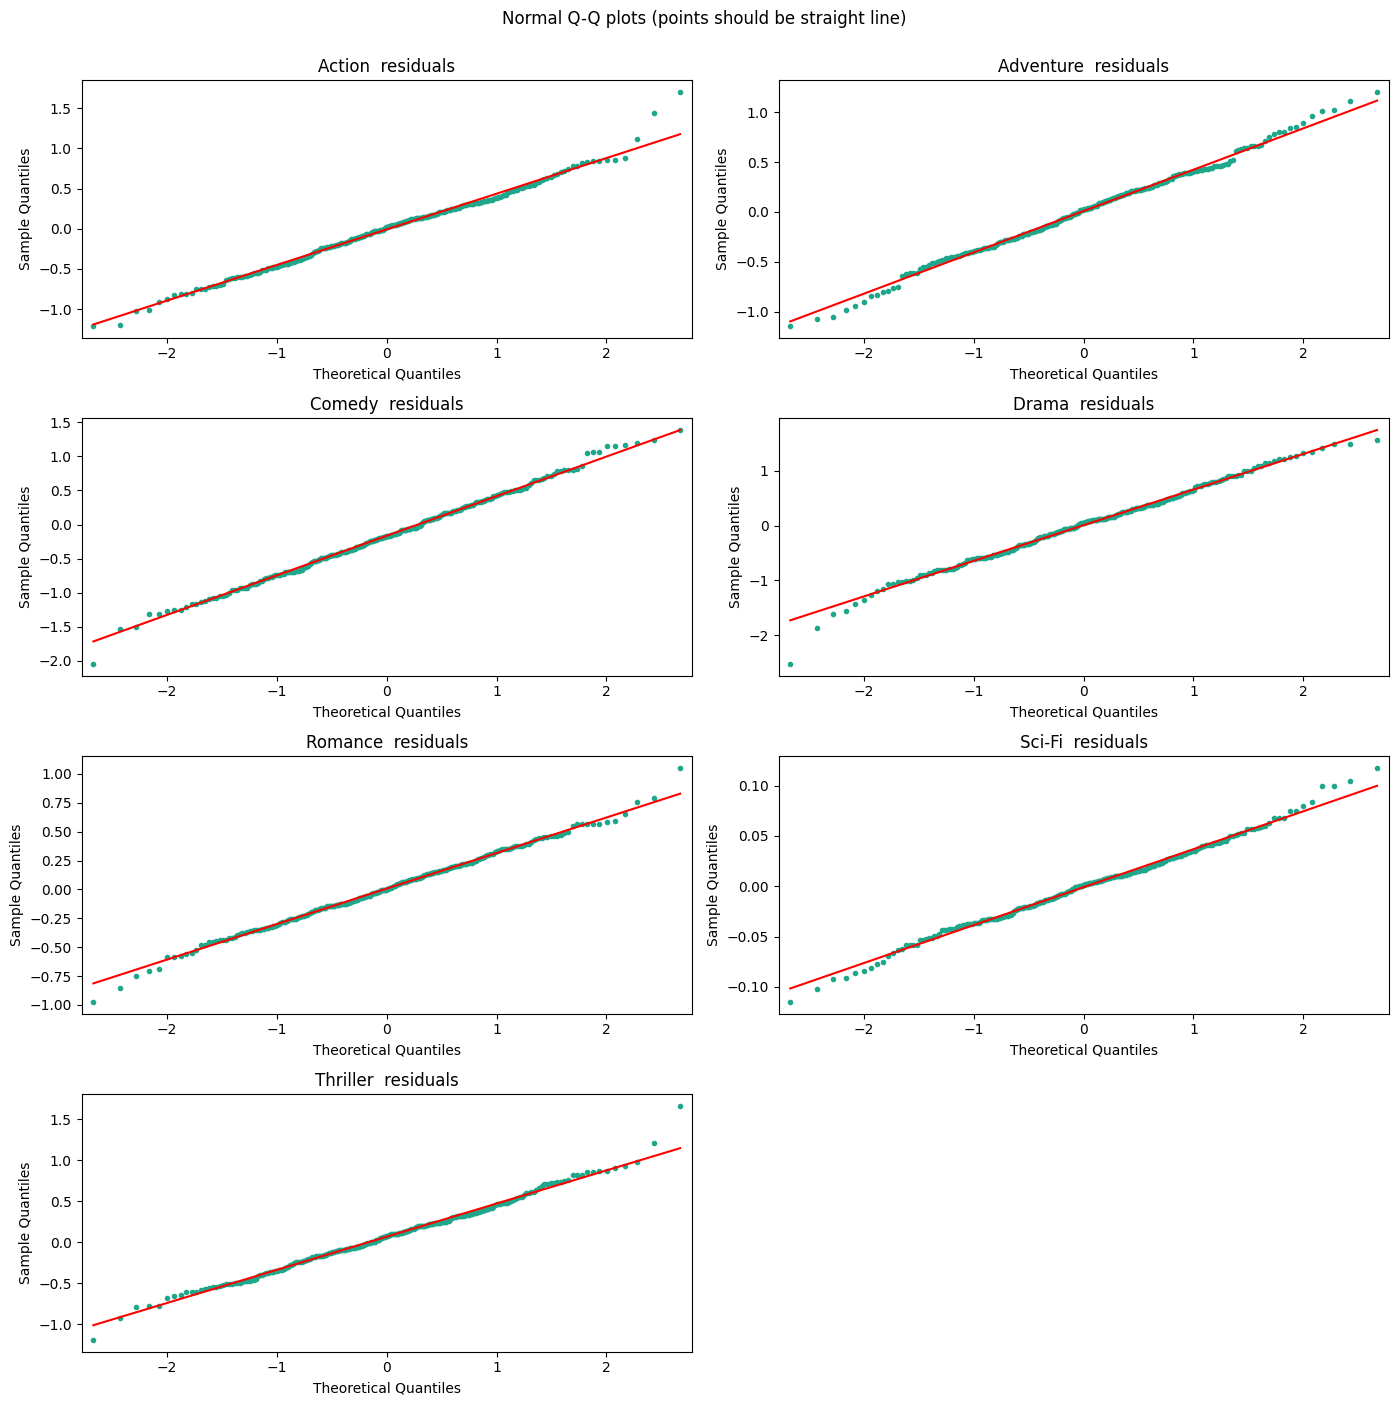

In [7]:
# Q-Q plots against the normal distribution
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
for ax, g in zip(axes.ravel(), genres):
    sm.qqplot(residuals_clean[g], line="s", ax=ax, markersize=3, markerfacecolor="#1EA78A", markeredgecolor="#1EA78A")
    ax.set_title(f"{g}  residuals")
axes.ravel()[-1].axis("off")
fig.suptitle("Normal Q-Q plots (points should be straight line)", y=1.0)
plt.tight_layout()
plt.savefig("../outputs/figures/residuals_qqplots.png", dpi=300, bbox_inches="tight")
plt.show()

<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Jarque Bera Test

</div>

Jarque-Bera test checks whether model residuals are normally distributed using skewness and kurtosis. It helps evaluate the normality assumption, but normality is not mandatory for every forecasting model.

In [14]:
jb_rows = {}
for g in genres:
    r = residuals_clean[g]
    jb = stats.jarque_bera(r)
    t = stats.ttest_1samp(r, 0.0)
    jb_rows[g] = {"JB_p": jb.pvalue.round(3),
                  "normal (p>0.05)": jb.pvalue > 0.05}

jb_table = pd.DataFrame(jb_rows).T
display(jb_table.round(4))
jb_table.to_csv("../outputs/tables/jarque_bera_residual_normality.csv")

,JB_p,normal (p>0.05)
Action,0.076,True
Adventure,0.894,True
Comedy,0.953,True
Drama,0.145,True
Romance,0.708,True
Sci-Fi,0.36,True
Thriller,0.066,True


<div style="
background:#1EA78A;
padding:12px;
border-left:8px solid #90c463;
border-radius:8px;
color:white;
font-size:24px;
font-weight:bold;">

Ljung Box Test

</div>

Ljung-Box test = Checks whether residuals are white noise with respect to autocorrelation.

High p-value → No significant evidence of autocorrelation.

Low p-value → Residual autocorrelation remains; the model may be missing temporal patterns.

In [10]:
lb_rows = {}

for g in genres:
    r = residuals_clean[g]
    lb = sm.stats.acorr_ljungbox(r, lags=[12], return_df=True)
    lb_rows[g] = {
        "LB_stat": lb["lb_stat"].iloc[0],
        "p-value": lb["lb_pvalue"].iloc[0],
        "white noise (p>0.05)": lb["lb_pvalue"].iloc[0] > 0.05,
    }

lb_table = pd.DataFrame(lb_rows).T
display(lb_table.round(4))
#lb_table.to_csv("../outputs/tables/ljung_box_residual_autocorrelation.csv")

,LB_stat,p-value,white noise (p>0.05)
Action,15.646694,0.207959,True
Adventure,92.895187,0.0,False
Comedy,70.125251,0.0,False
Drama,24.904123,0.015284,False
Romance,23.558108,0.023345,False
Sci-Fi,26.024875,0.010647,False
Thriller,30.880973,0.002054,False
